# part 1: data exploration and preprocessing

This notebook audits the real merged dataset, explores it, creates leakage-free past features, and saves development data, a future test year, and validation folds. It does not train a forecasting model.

We import simple libraries and fix the random seed so that the notebook is reproducible.

In [1]:
from pathlib import Path
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GroupKFold, KFold

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))
data_dir = project_root / "data"
processed_dir = data_dir / "processed"
results_dir = project_root / "results"
figures_dir = project_root / "figures"
folds_dir = project_root / "folds"
processed_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
folds_dir.mkdir(parents=True, exist_ok=True)
print("python version:", sys.version.split()[0])
from src.preprocessing import load_combined_data


python version: 3.10.5


The project folder has three CSV files. The combined file already contains PM2.5 and the GEE variables in the same rows, so it is the most suitable starting file.

In [2]:
source = data_dir / "raw" / "combined_gee_pm25.csv"
df = load_combined_data(source)
print("source file:", source)
print("kaggle source: https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin20162026/")
print("license: not found in the project files, to check on the kaggle page")
print("shape:", df.shape)
print("columns:", list(df.columns))
display(df.head())

source file: C:\Users\LENOVO\Documents\ds project\data\raw\combined_gee_pm25.csv
kaggle source: https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin20162026/
license: not found in the project files, to check on the kaggle page
shape: (41718, 15)
columns: ['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


This table shows the real data types. I do not add names for variables that are not present in the file.

In [3]:
print(df.dtypes)
print("date range as text:", df["date"].min(), "to", df["date"].max())
print("numeric columns:", list(df.select_dtypes(include="number").columns))
print("units: pm25 is micrograms per cubic metre from the project brief; temperature is celsius; pressure is mb; other units are not given in the files")

date                    object
datetime_utc            object
id                       int64
latitude               float64
longitude              float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
pm25                   float64
sensor_name             object
dtype: object
date range as text: 2016-11-25 to 2026-04-06
numeric columns: ['id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25']
units: pm25 is micrograms per cubic metre from the project brief; temperature is celsius; pressure is mb; other units are not given in the files


I parse both date columns and check whether parsing creates invalid timestamps. The separate `datetime_utc` column is consistent with the daily `date` column in this file.

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], errors="coerce")
print("invalid date values:", df["date"].isna().sum())
print("invalid datetime values:", df["datetime_utc"].isna().sum())
print("date range:", df["date"].min().date(), "to", df["date"].max().date())
print("latitude range:", df["latitude"].min(), "to", df["latitude"].max())
print("longitude range:", df["longitude"].min(), "to", df["longitude"].max())
print("sensor names:", df["sensor_name"].nunique(), "and numeric ids:", df["id"].nunique())

invalid date values: 0
invalid datetime values: 0
date range: 2016-11-25 to 2026-04-06
latitude range: 36.13331699932336 to 43.5302972250095
longitude range: -5.663499999930786 to 9.136389000276088
sensor names: 94 and numeric ids: 98


The coordinate ranges are plausible for the Mediterranean study area. The numeric `id` is a GEE location identifier, while `sensor_name` identifies the repeated PM2.5 station observations. I will use `sensor_name` for station grouping because it is the air-quality station label.

We count missing values and duplicate keys before cleaning. This gives a baseline for the audit.

In [5]:
missing = pd.DataFrame({"count": df.isna().sum()})
missing["percentage"] = 100 * missing["count"] / len(df)
display(missing)
print("full-row duplicates:", df.duplicated().sum())
key_columns = ["date", "latitude", "longitude", "sensor_name"]
print("duplicates on date, coordinates and sensor name:", df.duplicated(key_columns).sum())
print("observations per sensor summary:")
display(df.groupby("sensor_name").size().describe())

,count,percentage
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883


full-row duplicates: 0


duplicates on date, coordinates and sensor name: 0
observations per sensor summary:


count      94.000000
mean      443.808511
std       284.020796
min         1.000000
25%       199.500000
50%       464.000000
75%       680.000000
max      1047.000000
dtype: float64

There are repeated measurements from the same stations. This means rows are not independent, so spatial grouped validation is needed later. Missingness is present for NO2, CO, and O3 and will be handled inside a training-fold pipeline later.

The PM2.5 cleaning rules come from the project brief. I report each removal reason separately before changing the data.

In [6]:
initial_rows = len(df)
missing_pm25 = df["pm25"].isna()
invalid_low = df["pm25"].notna() & (df["pm25"] <= 0)
invalid_high = df["pm25"].notna() & (df["pm25"] >= 500)
cleaning_counts = pd.DataFrame({
    "reason": ["initial rows", "missing pm25", "pm25 <= 0", "pm25 >= 500"],
    "rows": [initial_rows, int(missing_pm25.sum()), int(invalid_low.sum()), int(invalid_high.sum())]
})
display(cleaning_counts)

,reason,rows
0,initial rows,41718
1,missing pm25,0
2,pm25 <= 0,727
3,pm25 >= 500,8


Rows with missing or invalid PM2.5 cannot be targets for this task, so I remove them. Exact duplicate rows are also removed. Key duplicates were zero, so no repeated station-day measurements need a special aggregation decision.

In [7]:
keep = ~(missing_pm25 | invalid_low | invalid_high)
clean = df.loc[keep].copy()
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
clean = clean.sort_values(["sensor_name", "date"]).reset_index(drop=True)
cleaning_counts = pd.concat([cleaning_counts, pd.DataFrame({"reason": ["exact duplicates after invalid-row removal", "final cleaned rows"], "rows": [exact_duplicates, len(clean)]})], ignore_index=True)
display(cleaning_counts)

,reason,rows
0,initial rows,41718
1,missing pm25,0
2,pm25 <= 0,727
3,pm25 >= 500,8
4,exact duplicates after invalid-row removal,0
5,final cleaned rows,40983


The invalid PM2.5 sentinels are removed, but large valid values below 500 are kept. A high value can be a real pollution episode rather than a measurement error.

I create a long tidy audit table. Each row has one variable, one metric, and one value so that the different results fit in one CSV file.

In [8]:
audit_rows = []
for column in df.columns:
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_count", "value": float(df[column].isna().sum())})
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_percentage", "value": float(100 * df[column].isna().mean())})
for row in cleaning_counts.itertuples(index=False):
    audit_rows.append({"section": "cleaning", "variable": "pm25", "metric": row.reason, "value": float(row.rows)})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "rows", "value": float(len(df))})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "columns", "value": float(df.shape[1])})
audit_rows.append({"section": "audit", "variable": "sensor_name", "metric": "unique_stations", "value": float(clean["sensor_name"].nunique())})
audit_rows.append({"section": "audit", "variable": "date", "metric": "unique_dates", "value": float(clean["date"].nunique())})
exploratory = pd.DataFrame(audit_rows)

I summarize the numeric variables with the statistics requested in the brief. Identifiers and coordinates are shown for audit, but they will not be model features.

In [9]:
numeric_columns = clean.select_dtypes(include="number").columns.tolist()
numeric_summary = clean[numeric_columns].describe().T
numeric_summary["skewness"] = clean[numeric_columns].skew()
numeric_summary["kurtosis"] = clean[numeric_columns].kurtosis()
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
id,40983.0,52.725032,35.034045,0.000000,21.000000,50.000000,90.000000,109.000000,0.102677,-1.513270
latitude,40983.0,39.030362,2.231117,36.133317,36.841330,39.448330,40.051944,43.530297,0.396995,-0.686293
longitude,40983.0,-0.466409,3.829059,-5.663500,-3.612660,-0.406050,1.149600,9.136389,0.643840,0.158251
temperature_celsius,40983.0,18.271961,6.386195,-1.279053,12.965739,18.494734,23.787869,34.865831,-0.102340,-0.971192
pressure_mb,40983.0,993.817385,17.180014,930.317065,987.986366,997.728716,1005.366821,1033.662176,-1.086888,0.714344
wind_u,40983.0,0.343444,2.527802,-11.098723,-0.984837,0.205846,1.684241,9.661651,-0.177789,1.034201
wind_v,40983.0,-0.178770,1.385553,-10.860048,-0.730883,0.042730,0.661478,8.486383,-1.276639,4.389013
NO2,38576.0,0.000092,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483,2.122683,9.177522
CO,38576.0,0.031578,0.003893,0.013058,0.029041,0.031412,0.033827,0.097613,1.398186,13.768381
O3,38535.0,0.143550,0.014491,0.103899,0.134019,0.140472,0.151048,0.229322,1.150540,2.278098


The target distribution is usually right-skewed in pollution data. I show its shape, its log1p version for inspection only, and the shares above the two project thresholds.

pm25 skewness: 17.82910231943009
share above 25: 2.98 %
share above 50: 0.29 %


,count,median,mean,std
season,,,,
autumn,10003,7.470000,9.082521,12.019754
spring,9276,6.833333,8.251462,7.402640
summer,12766,8.500000,9.593868,7.210516
winter,8938,8.773333,10.935249,11.722205


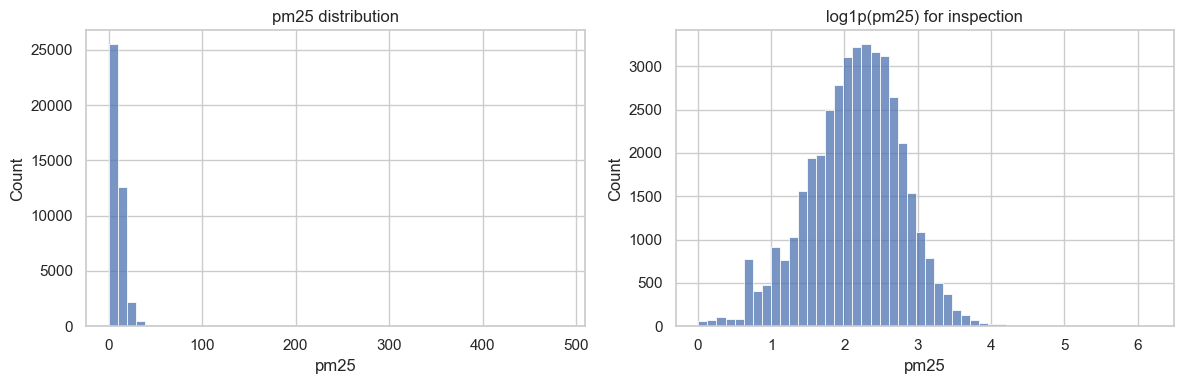

In [10]:
clean["month"] = clean["date"].dt.month
clean["year"] = clean["date"].dt.year
clean["season"] = clean["month"].map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
print("pm25 skewness:", clean["pm25"].skew())
print("share above 25:", round(100 * (clean["pm25"] > 25).mean(), 2), "%")
print("share above 50:", round(100 * (clean["pm25"] > 50).mean(), 2), "%")
display(clean.groupby("season")["pm25"].agg(["count", "median", "mean", "std"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean["pm25"], bins=50, ax=axes[0])
axes[0].set_title("pm25 distribution")
sns.histplot(np.log1p(clean["pm25"]), bins=50, ax=axes[1])
axes[1].set_title("log1p(pm25) for inspection")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_distribution.png", dpi=150)
plt.show()

A skewed target means RMSE will give extra weight to large errors, while MAE is less dominated by extreme days. We should keep the extreme episodes visible and report both metrics in the modeling part.

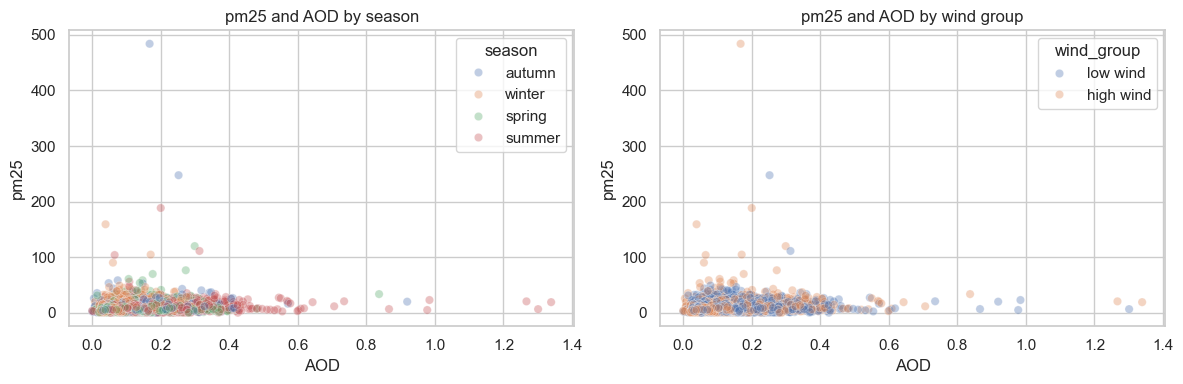

correlation by wind group


wind_group      
low wind    pm25    0.069112
high wind   pm25    0.109277
Name: AOD, dtype: float64

In [11]:
clean["wind_speed"] = np.sqrt(clean["wind_u"] ** 2 + clean["wind_v"] ** 2)
clean["wind_group"] = pd.qcut(clean["wind_speed"], q=2, labels=["low wind", "high wind"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=clean.sample(min(5000, len(clean)), random_state=SEED), x="AOD", y="pm25", hue="season", alpha=0.35, ax=axes[0])
axes[0].set_title("pm25 and AOD by season")
sns.scatterplot(data=clean.sample(min(5000, len(clean)), random_state=SEED), x="AOD", y="pm25", hue="wind_group", alpha=0.35, ax=axes[1])
axes[1].set_title("pm25 and AOD by wind group")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_predictor_relationships.png", dpi=150)
plt.show()
print("correlation by wind group")
display(clean.groupby("wind_group", observed=True)[["pm25", "AOD"]].corr().loc[(slice(None), "pm25"), "AOD"])

The time series decision is yes: dates parse correctly and there are many repeated daily observations, so a day-ahead scenario and past-only lag features are appropriate. Gaps must still be checked per station, and lag values across gaps will be set to missing.

I measure daily regularity per station. The percentage of dates present and the longest gap show why ordinary row shifts would be unsafe.

In [12]:
station_rows = []
for station, group in clean.groupby("sensor_name"):
    dates = group["date"].drop_duplicates().sort_values()
    gaps = dates.diff().dt.days.dropna()
    expected_days = (dates.max() - dates.min()).days + 1
    station_rows.append({"station": station, "rows": len(group), "unique_days": len(dates), "days_present_percent": 100 * len(dates) / expected_days, "longest_gap_days": int(gaps.max()) if len(gaps) else 0, "duplicate_station_days": int(group.duplicated(["date"]).sum())})
station_regularity = pd.DataFrame(station_rows)
display(station_regularity.describe())
print("stations with duplicate dates:", int((station_regularity["duplicate_station_days"] > 0).sum()))
print("overall longest gap in days:", int(station_regularity["longest_gap_days"].max()))

,rows,unique_days,days_present_percent,longest_gap_days,duplicate_station_days
count,91.000000,91.000000,91.000000,91.000000,91.000000
mean,450.362637,450.340659,49.439628,113.659341,0.021978
std,272.658538,272.651720,15.702141,261.453086,0.147424
min,4.000000,4.000000,4.525862,1.000000,0.000000
25%,220.000000,220.000000,38.196286,13.500000,0.000000
50%,468.000000,468.000000,50.062735,114.000000,0.000000
75%,677.500000,677.500000,59.297797,121.500000,0.000000
max,1042.000000,1042.000000,100.000000,2383.000000,1.000000


stations with duplicate dates: 2
overall longest gap in days: 2383


For autocorrelation diagnostics I use the daily mean PM2.5 across stations. This avoids choosing one short station and gives one regular daily series after reindexing missing dates.

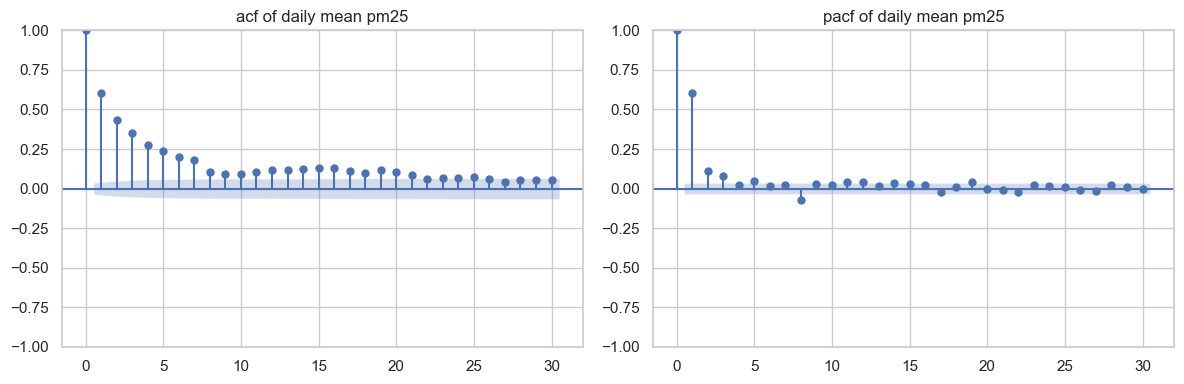

ljung-box p-value at lag 7: 0.0
adf statistic: -9.488132715245982
adf p-value: 3.71482956627142e-16


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_36412\415030314.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(diagnostic_series)


In [13]:
daily_mean = clean.groupby("date")["pm25"].mean().asfreq("D")
daily_mean = daily_mean.interpolate(limit=7)
diagnostic_series = daily_mean.dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diagnostic_series, lags=30, ax=axes[0])
axes[0].set_title("acf of daily mean pm25")
plot_pacf(diagnostic_series, lags=30, ax=axes[1], method="ywm")
axes[1].set_title("pacf of daily mean pm25")
plt.tight_layout()
plt.savefig(figures_dir / "acf_pacf_daily_mean_pm25.png", dpi=150)
plt.show()
ljung = acorr_ljungbox(diagnostic_series, lags=[7], return_df=True)
adf = adfuller(diagnostic_series)
print("ljung-box p-value at lag 7:", float(ljung["lb_pvalue"].iloc[0]))
print("adf statistic:", float(adf[0]))
print("adf p-value:", float(adf[1]))

A small Ljung-Box p-value would indicate temporal dependence, which supports lags. The ADF result is only a stationarity diagnostic; even if the level is not stationary, time-aware validation remains necessary.

I summarize drift by month and year using medians, IQR, and high-concentration frequencies.

,median,q25,q75,mean,above_25_percent,above_50_percent
month,,,,,,
1,8.145129,4.336458,13.234375,10.386266,4.848285,0.395778
2,9.250000,5.000000,14.391304,11.278159,6.617411,0.546097
3,7.256875,4.419819,12.000000,9.485719,3.997093,0.617733
4,6.438750,3.943095,9.809375,7.697311,1.300867,0.266845
5,6.872958,4.301250,10.024694,7.759310,0.822462,0.226886
6,7.811962,4.905844,12.000000,9.086287,1.901781,0.048146
7,8.301400,5.049632,11.964664,9.127772,1.305970,0.163246
8,9.362083,6.000000,13.852500,10.543708,2.636448,0.231267
9,7.000000,4.147129,10.103283,8.106971,1.392370,0.139237


,median,q25,q75,mean,above_25_percent,above_50_percent
year,,,,,,
2016,10.166667,6.944444,14.000000,10.889285,1.801802,0.000000
2017,7.666667,4.643189,11.939967,9.460013,3.827977,0.330813
2018,7.018750,4.440476,10.611979,7.879574,0.396825,0.000000
2019,6.718254,3.000000,12.387440,8.654724,4.288939,0.056433
2020,5.714286,3.233032,9.792857,7.554598,2.063443,0.092393
2021,6.800000,3.714286,11.141234,8.854864,2.380952,0.589971
2022,8.125000,4.800000,12.165000,9.619613,2.018571,0.464271
2023,9.000000,5.791497,13.225333,10.223157,2.444444,0.203704
2024,8.000000,5.069741,12.000000,9.612762,3.153775,0.207182


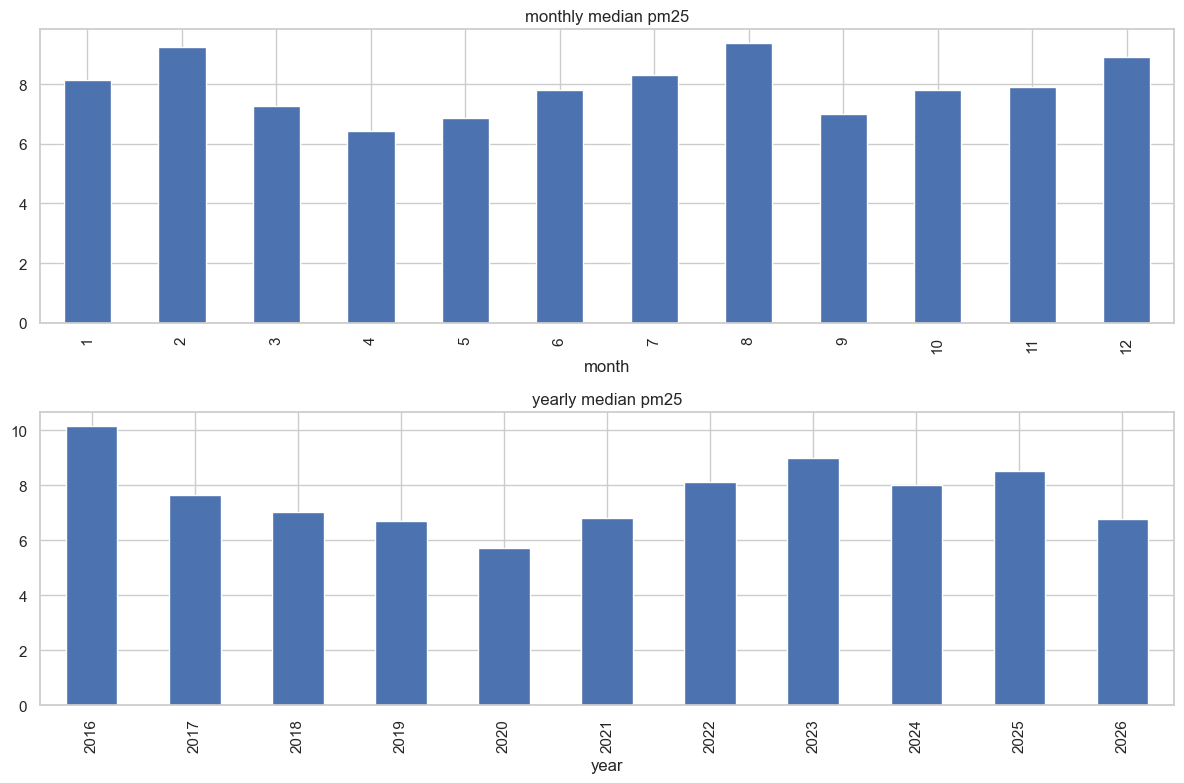

In [14]:
monthly = clean.groupby("month")["pm25"].agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), mean="mean")
yearly = clean.groupby("year")["pm25"].agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), mean="mean")
monthly["above_25_percent"] = clean.groupby("month")["pm25"].apply(lambda x: 100 * (x > 25).mean())
monthly["above_50_percent"] = clean.groupby("month")["pm25"].apply(lambda x: 100 * (x > 50).mean())
yearly["above_25_percent"] = clean.groupby("year")["pm25"].apply(lambda x: 100 * (x > 25).mean())
yearly["above_50_percent"] = clean.groupby("year")["pm25"].apply(lambda x: 100 * (x > 50).mean())
display(monthly)
display(yearly)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
monthly["median"].plot(kind="bar", ax=axes[0], title="monthly median pm25")
yearly["median"].plot(kind="bar", ax=axes[1], title="yearly median pm25")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_monthly_yearly_drift.png", dpi=150)
plt.show()

These patterns describe possible seasonality and drift. The final test year is kept separate, so later model results will show whether patterns learned before it transfer to the future year.

I now create past-only features. A shift is accepted only when the row is exactly the required number of days after the past row for the same sensor. This prevents a lag from jumping over a multi-day gap.

In [15]:
features = clean.copy()
features = features.sort_values(["sensor_name", "date"]).reset_index(drop=True)
feature_groups = {"AOD": [], "NO2_CO_O3": [], "meteorological": [], "calendar": [], "lag_rolling": []}
lag_sources = {"AOD": [1, 2, 3], "NO2": [1], "pm25": [1, 2, 3, 7]}
for column, lags in lag_sources.items():
    for lag in lags:
        name = column + "_lag_" + str(lag)
        features[name] = features.groupby("sensor_name")[column].shift(lag)
        day_difference = features.groupby("sensor_name")["date"].diff(lag).dt.days
        features.loc[day_difference != lag, name] = np.nan
        feature_groups["lag_rolling"].append(name)

for column in ["AOD", "temperature_celsius", "NO2"]:
    name = column + "_diff_1"
    features[name] = features.groupby("sensor_name")[column].diff(1)
    day_difference = features.groupby("sensor_name")["date"].diff(1).dt.days
    features.loc[day_difference != 1, name] = np.nan
    feature_groups["lag_rolling"].append(name)

for station, group in features.groupby("sensor_name"):
    index = group.index
    dates = group["date"]
    for column in ["AOD", "temperature_celsius", "NO2"]:
        for window in [3, 7]:
            mean_name = column + "_past_mean_" + str(window)
            std_name = column + "_past_std_" + str(window)
            shifted = group[column].shift(1)
            features.loc[index, mean_name] = shifted.rolling(window).mean().to_numpy()
            features.loc[index, std_name] = shifted.rolling(window).std().to_numpy()
            complete_days = dates.diff(window).dt.days == window
            features.loc[index[~complete_days.fillna(False)], [mean_name, std_name]] = np.nan
            feature_groups["lag_rolling"].extend([mean_name, std_name])
    shifted_aod = group["AOD"].shift(1)
    extreme_name = "AOD_past_max_7"
    features.loc[index, extreme_name] = shifted_aod.rolling(7).max().to_numpy()
    complete_days = dates.diff(7).dt.days == 7
    features.loc[index[~complete_days.fillna(False)], extreme_name] = np.nan

features["AOD_change_3"] = features.groupby("sensor_name")["AOD"].diff(3)
day_difference_3 = features.groupby("sensor_name")["date"].diff(3).dt.days
features.loc[day_difference_3 != 3, "AOD_change_3"] = np.nan
feature_groups["lag_rolling"].append("AOD_change_3")
features["day_of_year_sin"] = np.sin(2 * np.pi * features["date"].dt.dayofyear / 365.25)
features["day_of_year_cos"] = np.cos(2 * np.pi * features["date"].dt.dayofyear / 365.25)
feature_groups["calendar"] = ["day_of_year_sin", "day_of_year_cos"]
print("created features:", sum(len(value) for value in feature_groups.values()))

created features: 1106


The project asks for time since the last high-AOD day. I define high AOD using the development period only, then calculate the previous high-AOD date separately for each sensor. The first rows and rows without a past event remain missing.

In [16]:
development_dates = features.loc[features["date"].dt.year < 2025, "AOD"]
high_aod_threshold = development_dates.quantile(0.75)
features["previous_high_aod_date"] = pd.NaT
for station, group in features.groupby("sensor_name"):
    previous_high = group["date"].where(group["AOD"] >= high_aod_threshold).shift(1).ffill()
    features.loc[group.index, "previous_high_aod_date"] = previous_high.to_numpy()
features["days_since_high_AOD"] = (features["date"] - features["previous_high_aod_date"]).dt.days
features = features.drop(columns=["previous_high_aod_date"])
feature_groups["lag_rolling"].append("days_since_high_AOD")
print("high AOD threshold from development period:", high_aod_threshold)
print("missing days_since_high_AOD values:", features["days_since_high_AOD"].isna().sum())

high AOD threshold from development period:

 0.197
missing days_since_high_AOD values: 719


A quick check confirms that a one-day lag is missing when the previous available row is not exactly one day earlier. This is why we do not use a simple shift without a date check.

In [17]:
check = features[["sensor_name", "date", "AOD_lag_1"]].copy()
check["previous_date"] = check.groupby("sensor_name")["date"].shift(1)
check["gap_days"] = (check["date"] - check["previous_date"]).dt.days
gap_rows = check[check["gap_days"] > 1]
print("rows after a multi-day gap:", len(gap_rows))
print("such rows with a non-missing one-day AOD lag:", int(gap_rows["AOD_lag_1"].notna().sum()))
display(gap_rows.head())

rows after a multi-day gap: 13631
such rows with a non-missing one-day AOD lag: 0


,sensor_name,date,AOD_lag_1,previous_date,gap_days
1,AIX CENTRE ECOLE ART,2024-02-03,NaN,2024-01-31,3.0
2,AIX CENTRE ECOLE ART,2024-02-05,NaN,2024-02-03,2.0
3,AIX CENTRE ECOLE ART,2024-02-11,NaN,2024-02-05,6.0
4,AIX CENTRE ECOLE ART,2024-02-13,NaN,2024-02-11,2.0
5,AIX CENTRE ECOLE ART,2024-02-17,NaN,2024-02-13,4.0


Station names, coordinates, numeric IDs, and dates are metadata only. The feature list below excludes all of them and excludes same-day PM2.5, so the target is not used as a same-day input.

In [18]:
for key in feature_groups:
    feature_groups[key] = sorted(set(feature_groups[key]))
feature_groups["AOD"] = [column for column in ["AOD"] if column in features.columns]
feature_groups["NO2_CO_O3"] = [column for column in ["NO2", "CO", "O3"] if column in features.columns]
feature_groups["meteorological"] = [column for column in ["temperature_celsius", "pressure_mb", "wind_u", "wind_v", "wind_speed"] if column in features.columns]
feature_list = []
for group in feature_groups.values():
    feature_list.extend(group)
feature_list = sorted(set(feature_list))
print("feature groups:")
for key, values in feature_groups.items():
    print(key, values)
with open(processed_dir / "feature_groups.json", "w", encoding="utf-8") as file:
    json.dump(feature_groups, file, indent=2)

feature groups:
AOD ['AOD']
NO2_CO_O3 ['NO2', 'CO', 'O3']
meteorological ['temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'wind_speed']
calendar ['day_of_year_cos', 'day_of_year_sin']
lag_rolling ['AOD_change_3', 'AOD_diff_1', 'AOD_lag_1', 'AOD_lag_2', 'AOD_lag_3', 'AOD_past_mean_3', 'AOD_past_mean_7', 'AOD_past_std_3', 'AOD_past_std_7', 'NO2_diff_1', 'NO2_lag_1', 'NO2_past_mean_3', 'NO2_past_mean_7', 'NO2_past_std_3', 'NO2_past_std_7', 'days_since_high_AOD', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_3', 'pm25_lag_7', 'temperature_celsius_diff_1', 'temperature_celsius_past_mean_3', 'temperature_celsius_past_mean_7', 'temperature_celsius_past_std_3', 'temperature_celsius_past_std_7']


The last complete calendar year is 2025. The available 2026 data stop in April, so 2026 is partial and is not used as the independent test year. I save 2025 as test, dates before 2025 as development, and leave partial 2026 outside both sets.

In [19]:
test_year = 2025
test_mask = features["date"].dt.year == test_year
dev_mask = features["date"].dt.year < test_year
post_test_mask = features["date"].dt.year > test_year
test = features.loc[test_mask].copy()
dev = features.loc[dev_mask].copy()
post_test = features.loc[post_test_mask].copy()
print("development rows:", len(dev))
print("test rows:", len(test))
print("partial post-test rows held outside both:", len(post_test))
print("test dates:", test["date"].min().date(), "to", test["date"].max().date())
dev.to_csv(processed_dir / "dev.csv", index=False, encoding="utf-8")
test.to_csv(processed_dir / "test.csv", index=False, encoding="utf-8")
features.to_csv(processed_dir / "features_all.csv", index=False, encoding="utf-8")

development rows: 31286
test rows: 8149
partial post-test rows held outside both: 1548
test dates: 2025-01-01 to 2025-12-31


I build the two required exploration CSV files. The temporal table contains the main timestamp, regularity, drift, and diagnostic values.

In [20]:
for column in numeric_columns:
    if column in clean.columns:
        for metric in ["min", "max", "mean", "std", "25%", "50%", "75%", "skewness", "kurtosis"]:
            if metric in numeric_summary.columns:
                exploratory.loc[len(exploratory)] = ["numeric_summary", column, metric, float(numeric_summary.loc[column, metric])]
for column in ["NO2", "CO", "O3"]:
    for month, group in clean.groupby("month"):
        exploratory.loc[len(exploratory)] = ["missing_by_month", column, "month_" + str(month), float(group[column].isna().sum())]
    for station, group in clean.groupby("sensor_name"):
        exploratory.loc[len(exploratory)] = ["missing_by_station", column, station, float(group[column].isna().sum())]
exploratory.to_csv(results_dir / "Exploratory_Data.csv", index=False, encoding="utf-8", decimal=".")
temporal_rows = []
def add_temporal(variable, metric, value):
    temporal_rows.append({"section": "temporal", "variable": variable, "metric": metric, "value": float(value)})
add_temporal("date", "unique_dates", clean["date"].nunique())
add_temporal("date", "invalid_dates", df["date"].isna().sum())
add_temporal("station", "number_of_stations", clean["sensor_name"].nunique())
add_temporal("station", "longest_gap_days", station_regularity["longest_gap_days"].max())
add_temporal("station", "mean_days_present_percent", station_regularity["days_present_percent"].mean())
add_temporal("pm25", "ljung_box_pvalue_lag_7", ljung["lb_pvalue"].iloc[0])
add_temporal("pm25", "adf_statistic", adf[0])
add_temporal("pm25", "adf_pvalue", adf[1])
for year, value in yearly["median"].items():
    add_temporal("pm25", "median_year_" + str(year), value)
for month, value in monthly["median"].items():
    add_temporal("pm25", "median_month_" + str(month), value)
temporal_results = pd.DataFrame(temporal_rows)
temporal_results.to_csv(results_dir / "Exploratory_temporal.csv", index=False, encoding="utf-8", decimal=".")
print("saved EDA tables")

saved EDA tables


The preprocessing pipeline is demonstrated on the first temporal training fold only. Median values and missingness indicators are fitted on training data, then applied to validation data. No model is trained.

In [21]:
model_features = [column for column in feature_list if column in dev.columns]
X_dev = dev[model_features]
y_dev = dev["pm25"]
unique_dev_dates = np.array(sorted(dev["date"].dropna().unique()))
date_splitter = TimeSeriesSplit(n_splits=5, gap=1)
date_train, date_val = next(date_splitter.split(unique_dev_dates))
train_dates = set(unique_dev_dates[date_train])
val_dates = set(unique_dev_dates[date_val])
train_rows = dev["date"].isin(train_dates)
val_rows = dev["date"].isin(val_dates)
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler())
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, model_features)
])
X_train_transformed = preprocessor.fit_transform(X_dev.loc[train_rows])
X_val_transformed = preprocessor.transform(X_dev.loc[val_rows])
print("training rows:", train_rows.sum(), "validation rows:", val_rows.sum())
print("transformed train shape:", X_train_transformed.shape)
print("transformed validation shape:", X_val_transformed.shape)
print("missing after train transform:", np.isnan(X_train_transformed).sum())
print("missing after validation transform:", np.isnan(X_val_transformed).sum())

training rows: 3531 validation rows: 3433
transformed train shape: (3531, 64)
transformed validation shape: (3433, 64)
missing after train transform: 0
missing after validation transform: 0


The NO2, CO, and O3 correlations are checked separately in each temporal training fold. If their correlations changed strongly, KNN imputation would be hard to justify. Here the simple median pipeline is the default.

In [22]:
sentinel_columns = [column for column in ["NO2", "CO", "O3"] if column in dev.columns]
fold_correlations = []
for fold_number, (train_date_idx, val_date_idx) in enumerate(date_splitter.split(unique_dev_dates), start=1):
    fold_train_dates = set(unique_dev_dates[train_date_idx])
    fold_train = dev[dev["date"].isin(fold_train_dates)]
    fold_correlations.append(fold_train[sentinel_columns].corr())
max_difference = 0
for first_index in range(len(fold_correlations)):
    for second_index in range(first_index + 1, len(fold_correlations)):
        difference = (fold_correlations[first_index] - fold_correlations[second_index]).abs().to_numpy().max()
        max_difference = max(max_difference, difference)
print("sentinel columns:", sentinel_columns)
print("maximum absolute correlation difference across training folds:", max_difference)
print("decision: use training-fold median imputation with indicators; do not use KNN imputation in this part")

sentinel columns: ['NO2', 'CO', 'O3']
maximum absolute correlation difference across training folds: 0.14232233034128958
decision: use training-fold median imputation with indicators; do not use KNN imputation in this part


Finally, I save the three fold schemes. Temporal folds split unique dates, spatial folds keep each sensor in one side only, and random folds are diagnostic only.

In [23]:
def save_folds(folds, path):
    simple_folds = []
    for train_index, validation_index in folds:
        simple_folds.append({"train_idx": [int(value) for value in train_index], "val_idx": [int(value) for value in validation_index]})
    with open(path, "w", encoding="utf-8") as file:
        json.dump(simple_folds, file, indent=2)
    return simple_folds

temporal_folds = []
for train_date_idx, val_date_idx in TimeSeriesSplit(n_splits=5, gap=1).split(unique_dev_dates):
    train_date_values = set(unique_dev_dates[train_date_idx])
    val_date_values = set(unique_dev_dates[val_date_idx])
    temporal_folds.append((np.where(dev["date"].isin(train_date_values))[0], np.where(dev["date"].isin(val_date_values))[0]))
spatial_folds = list(GroupKFold(n_splits=5).split(dev, y_dev, groups=dev["sensor_name"]))
standard_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(dev, y_dev))
save_folds(temporal_folds, folds_dir / "folds_temporal.json")
save_folds(spatial_folds, folds_dir / "folds_spatial.json")
save_folds(standard_folds, folds_dir / "folds_standard.json")
print("saved fold files")

saved fold files


These checks prove the important split rules: temporal validation dates are not in training, spatial stations are not shared, and no test row is in development.

temporal fold 1 train 3531 validation 3433 overlapping dates 0
temporal fold 2 train 6949 validation 4215 overlapping dates 0
temporal fold 3 train 11153 validation 6018 overlapping dates 0
temporal fold 4 train 17193 validation 6152 overlapping dates 0


temporal fold 5 train 23320 validation 7936 overlapping dates 0
spatial fold 1 train stations 57 validation stations 13 overlap 0
spatial fold 2 train stations 57 validation stations 13 overlap 0


spatial fold 3 train stations 54 validation stations 16 overlap 0
spatial fold 4 train stations 56 validation stations 14 overlap 0
spatial fold 5 train stations 56 validation stations 14 overlap 0
development rows in test year: 0


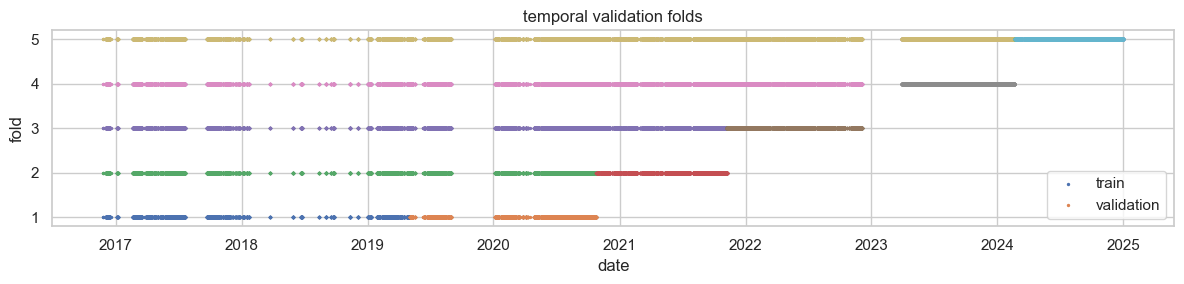

In [24]:
for number, (train_index, val_index) in enumerate(temporal_folds, start=1):
    train_dates = set(dev.iloc[train_index]["date"])
    val_dates = set(dev.iloc[val_index]["date"])
    print("temporal fold", number, "train", len(train_index), "validation", len(val_index), "overlapping dates", len(train_dates & val_dates))
for number, (train_index, val_index) in enumerate(spatial_folds, start=1):
    train_stations = set(dev.iloc[train_index]["sensor_name"])
    val_stations = set(dev.iloc[val_index]["sensor_name"])
    print("spatial fold", number, "train stations", len(train_stations), "validation stations", len(val_stations), "overlap", len(train_stations & val_stations))
print("development rows in test year:", int((dev["date"].dt.year == test_year).sum()))
fig, ax = plt.subplots(figsize=(12, 3))
for number, (train_index, val_index) in enumerate(temporal_folds, start=1):
    ax.scatter(dev.iloc[train_index]["date"], [number] * len(train_index), s=2, label="train" if number == 1 else None)
    ax.scatter(dev.iloc[val_index]["date"], [number] * len(val_index), s=2, label="validation" if number == 1 else None)
ax.set_title("temporal validation folds")
ax.set_xlabel("date")
ax.set_ylabel("fold")
ax.legend()
plt.tight_layout()
plt.savefig(figures_dir / "temporal_folds.png", dpi=150)
plt.show()

Lead-lag correlations compare today's PM2.5 with a predictor from the same day and from the previous seven days. This is descriptive only, but it helps decide which past variables are reasonable candidates later.

variable,AOD,CO,NO2,O3,temperature_celsius,wind_speed
lag_days,,,,,,
0,0.149764,0.049208,0.312836,-0.110552,-0.127277,-0.211535
1,0.042123,0.080380,0.273891,-0.112476,-0.150777,-0.213673
2,-0.019537,0.084871,0.197075,-0.080980,-0.161722,-0.100809
3,-0.053612,0.063036,0.152014,-0.061497,-0.169684,-0.056861
4,-0.070886,0.062001,0.103159,-0.046092,-0.166823,-0.007717
5,-0.067596,0.037397,0.076964,-0.039945,-0.159192,0.033935
6,-0.073053,0.025256,0.089658,-0.053118,-0.150871,0.067067
7,-0.090999,0.019837,0.093037,-0.034439,-0.148706,0.031153


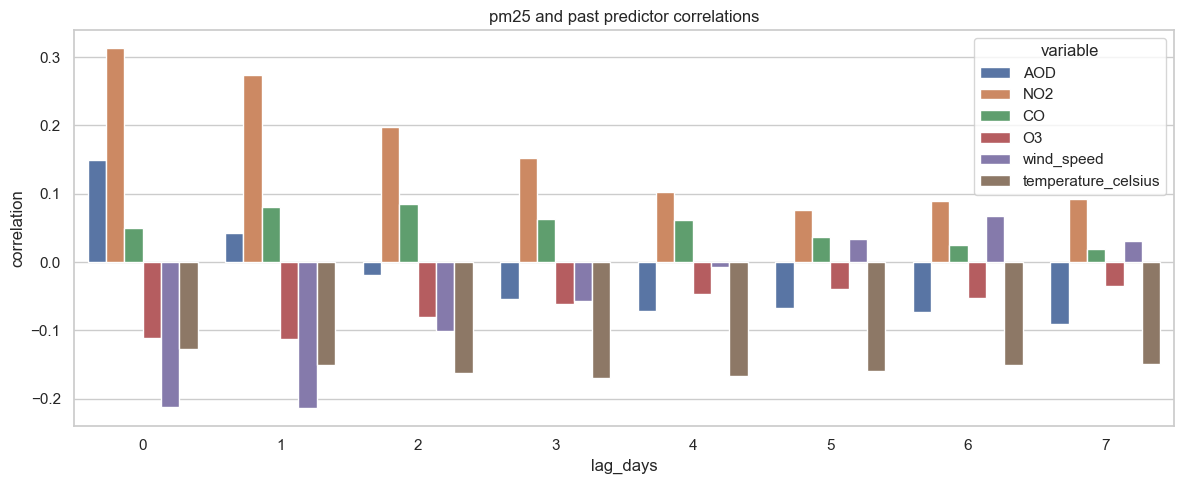

In [25]:
# here i average repeated station observations for each calendar day
lead_lag_columns = ["AOD", "NO2", "CO", "O3", "wind_speed", "temperature_celsius"]
daily_values = clean.groupby("date")[["pm25"] + lead_lag_columns].mean()
lead_lag_rows = []
for column in lead_lag_columns:
    for lag in range(8):
        past_values = daily_values[column].shift(lag)
        pair = pd.concat([daily_values["pm25"], past_values], axis=1).dropna()
        correlation = pair.iloc[:, 0].corr(pair.iloc[:, 1])
        lead_lag_rows.append({"variable": column, "lag_days": lag, "correlation": correlation})
lead_lag = pd.DataFrame(lead_lag_rows)
display(lead_lag.pivot(index="lag_days", columns="variable", values="correlation"))
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=lead_lag, x="lag_days", y="correlation", hue="variable", ax=ax)
ax.set_title("pm25 and past predictor correlations")
plt.tight_layout()
plt.savefig(figures_dir / "lead_lag_correlations.png", dpi=150)
plt.show()
# here i add the strongest lag for each available predictor to the temporal table
for column in lead_lag_columns:
    one_column = lead_lag[lead_lag["variable"] == column]
    best = one_column.iloc[one_column["correlation"].abs().argmax()]
    add_temporal(column, "strongest_absolute_correlation_lag", best["lag_days"])
    add_temporal(column, "strongest_absolute_correlation", best["correlation"])
pd.DataFrame(temporal_rows).to_csv(results_dir / "Exploratory_temporal.csv", index=False, encoding="utf-8", decimal=".")

The strongest correlations are candidates for later experiments, not proof that a variable causes PM2.5. The one-day-ahead setup still uses only information available before the target day.

## summary

This part keeps valid cleaned observations, flags but does not delete plausible PM2.5 extremes, and creates past-only features separately for each sensor. The target is PM2.5. Sensor names, numeric IDs, coordinates, and dates are metadata and are excluded from predictive features. The merged file already contains the GEE fields, so a second nearest-coordinate matching step was not needed. The partial 2026 rows are held outside both development and test. No forecasting model was trained.

## output files

- `results/Exploratory_Data.csv`: audit, missingness, cleaning counts, and numeric summaries.
- `results/Exploratory_temporal.csv`: timestamp, gap, autocorrelation, stationarity, and drift diagnostics.
- `figures/`: descriptive plots saved as PNG files.
- `data/processed/dev.csv`: development rows before 2025.
- `data/processed/test.csv`: the complete 2025 future test period.
- `data/processed/features_all.csv`: all engineered rows, including partial 2026 rows held out from dev and test.
- `data/processed/feature_groups.json`: feature families for later ablation.
- `folds/folds_temporal.json`: date-based folds with a one-day gap.
- `folds/folds_spatial.json`: station-grouped folds.
- `folds/folds_standard.json`: shuffled diagnostic folds.

The main data limitation is irregular station coverage: many station-day gaps exist, so gap-aware lag values are missing at starts and after gaps. The license was not present in the local project files and should be checked on Kaggle.